In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter1d, median_filter
from scipy import interpolate
from scipy.stats import linregress

In [3]:
def phase_detrend(f_GHz, Z):
    phi = np.unwrap(np.angle(Z))
    slope, intercept, *_ = linregress(f_GHz, phi)
    tau = slope / (2*np.pi)           
    trend = np.exp(1j*(2*np.pi*tau*f_GHz + intercept))
    return Z / trend, tau, intercept

def phase_detrend_hz(f_GHz, Z, deg=1):
    f_Hz = np.asarray(f_GHz)*1e9
    phi = np.unwrap(np.angle(Z))
    coefs = np.polyfit(f_Hz, phi, deg=deg)
    poly = np.poly1d(coefs)
    trend = np.exp(1j*poly(f_Hz))
    Z_dt = Z / trend
    return Z_dt, coefs

def coherent_gaussian_smooth(f_GHz, Z, sigma_GHz, half_width=3.5):
    f = np.asarray(f_GHz)
    Z = np.asarray(Z)
    out = np.empty_like(Z, dtype=np.complex128)
    for k in range(len(f)):
        mask = np.abs(f - f[k]) <= half_width*sigma_GHz
        ref = Z[k] / (np.abs(Z[k]) + 1e-15)
        Z_rot = Z[mask] * np.conj(ref)           
        w = np.exp(-0.5*((f[mask]-f[k])/sigma_GHz)**2)
        w /= (w.sum() + 1e-15)
        m = (w * Z_rot).sum()                    
        out[k] = m * ref                        
    return out

def interp_complex(f_src, Z_src, f_tgt, kind="linear", extrapolate=True):
    f_src = np.asarray(f_src)
    Z_src = np.asarray(Z_src)
    f_tgt = np.asarray(f_tgt)
    m = np.isfinite(f_src) & np.isfinite(Z_src.real) & np.isfinite(Z_src.imag)
    f, r, i = f_src[m], Z_src.real[m], Z_src.imag[m]
    if f.size < 2:
        return np.full_like(f_tgt, np.nan, dtype=complex)
    sorted_freqs = np.argsort(f)
    f, r, i = f[sorted_freqs], r[sorted_freqs], i[sorted_freqs]
    f_unique, indices = np.unique(f, return_index=True)
    r, i = r[indices], i[indices]
    f = f_unique

    fill = "extrapolate" if extrapolate else (np.nan, np.nan)

    amp_interp = interpolate.interp1d(f, r, kind=kind, bounds_error=False, fill_value=fill, assume_sorted=True)
    phase_interp = interpolate.interp1d(f, i, kind=kind, bounds_error=False, fill_value=fill, assume_sorted=True)

    return amp_interp(f_tgt) + 1j * phase_interp(f_tgt)

def smooth_complex(Z, sigma_bins):
    return gaussian_filter1d(Z.real, sigma_bins) + 1j * gaussian_filter1d(Z.imag, sigma_bins)

In [4]:
warm_scan_1ghz =  pd.read_csv("/Users/thachdang/Downloads/OnCryoWarmMeasurements/Tests_05052026/signalbetter_600to950_step1ghz_int300.txt", delimiter="\t")
warm_scan_pt1ghz =  pd.read_csv("/Users/thachdang/Downloads/OnCryoWarmMeasurements/Tests_05052026/signalbetter_600to950_steppt1ghz_int300.txt", delimiter="\t")
warm_scan_pt01ghz =  pd.read_csv("/Users/thachdang/Downloads/OnCryoWarmMeasurements/Tests_05052026/signalbetter_600to950_steppt01ghz_int300.txt", delimiter="\t")
warm_scan_shifted_pt01ghz =  pd.read_csv("/Users/thachdang/Downloads/OnCryoWarmMeasurements/Tests_05052026/signalshifted_840to870_steppt01ghz_int300.txt", delimiter="\t")



warm_data_1Ghz = warm_scan_1ghz[['Frequency Act (GHz)', 'Amplitude (via StrMod)','Phase (via StrMod)', "Timestamp (s).1"]]
warm_data_pt1Ghz = warm_scan_pt1ghz[['Frequency Act (GHz)', 'Amplitude (via StrMod)','Phase (via StrMod)', "Timestamp (s).1"]]
warm_data_pt01Ghz = warm_scan_pt01ghz[['Frequency Act (GHz)', 'Amplitude (via StrMod)','Phase (via StrMod)', "Timestamp (s).1"]]
warm_shifted_pt01Ghz = warm_scan_shifted_pt01ghz[['Frequency Act (GHz)', 'Amplitude (via StrMod)','Phase (via StrMod)', "Timestamp (s).1"]]


grid_frequencies = warm_scan_1ghz["Frequency Set (GHz)"]


warm_phasor_1Ghz = warm_data_1Ghz["Amplitude (via StrMod)"].to_numpy() * np.exp(1j * warm_data_1Ghz["Phase (via StrMod)"].to_numpy())
warm_phasor_pt1Ghz = warm_data_pt1Ghz["Amplitude (via StrMod)"].to_numpy() * np.exp(1j * warm_data_pt1Ghz["Phase (via StrMod)"].to_numpy())
warm_phasor_pt01Ghz = warm_data_pt01Ghz["Amplitude (via StrMod)"].to_numpy() * np.exp(1j * warm_data_pt01Ghz["Phase (via StrMod)"].to_numpy())
warm_shifted_phasor_pt01Ghz = warm_shifted_pt01Ghz["Amplitude (via StrMod)"].to_numpy() * np.exp(1j * warm_shifted_pt01Ghz["Phase (via StrMod)"].to_numpy())


warm_1Ghz_interp_phasor = interp_complex(warm_data_1Ghz["Frequency Act (GHz)"], warm_phasor_1Ghz, grid_frequencies, kind="linear", extrapolate=True)
warm_pt1Ghz_interp_phasor = interp_complex(warm_data_pt1Ghz["Frequency Act (GHz)"], warm_phasor_pt1Ghz, grid_frequencies, kind="linear", extrapolate=True)
mask = (grid_frequencies >= 800) & (grid_frequencies <= 900)
mask2 = (grid_frequencies >= 840) & (grid_frequencies <= 870)

warm_pt01Ghz_interp_phasor = interp_complex(warm_data_pt01Ghz["Frequency Act (GHz)"],
    warm_phasor_pt01Ghz,
    grid_frequencies[mask],
    kind="linear",
    extrapolate=True)

warm_pt01Ghz_shifted_interp_phasor = interp_complex(warm_shifted_pt01Ghz["Frequency Act (GHz)"],
    warm_shifted_phasor_pt01Ghz,
    grid_frequencies[mask2],
    kind="linear",
    extrapolate=True)

warm_amp_1Ghz, warm_ph_1Ghz = np.abs(warm_1Ghz_interp_phasor), np.angle(warm_1Ghz_interp_phasor)
warm_amp_pt1Ghz, warm_ph_pt1Ghz = np.abs(warm_pt1Ghz_interp_phasor), np.angle(warm_pt1Ghz_interp_phasor)
warm_amp_pt01Ghz, warm_ph_pt01Ghz = np.abs(warm_pt01Ghz_interp_phasor), np.angle(warm_pt01Ghz_interp_phasor)
warm_shifted_amp_pt01Ghz, warm_shifted_ph_pt01Ghz = np.abs(warm_pt01Ghz_shifted_interp_phasor), np.angle(warm_pt01Ghz_shifted_interp_phasor)


warm_1_Ghz_dt_phasor = warm_1Ghz_interp_phasor / np.exp(1j * np.poly1d(phase_detrend_hz(grid_frequencies, warm_1Ghz_interp_phasor, deg=1)[1])(grid_frequencies * 1e9))
warm_pt1_Ghz_dt_phasor = warm_pt1Ghz_interp_phasor / np.exp(1j * np.poly1d(phase_detrend_hz(grid_frequencies, warm_pt1Ghz_interp_phasor, deg=1)[1])(grid_frequencies * 1e9))
warm_pt01_Ghz_dt_phasor = warm_pt01Ghz_interp_phasor / np.exp(1j * np.poly1d(phase_detrend_hz(grid_frequencies[mask], warm_pt01Ghz_interp_phasor, deg=1)[1])(grid_frequencies[mask] * 1e9))
warm_pt01_shifted_Ghz_dt_phasor = warm_pt01Ghz_shifted_interp_phasor / np.exp(1j * np.poly1d(phase_detrend_hz(grid_frequencies[mask2], warm_pt01Ghz_shifted_interp_phasor, deg=1)[1])(grid_frequencies[mask2] * 1e9))


sigma_GHz = 10
warm_smooth_1Ghz = coherent_gaussian_smooth(grid_frequencies, warm_1_Ghz_dt_phasor, sigma_GHz)
warm_smooth_pt1Ghz = coherent_gaussian_smooth(grid_frequencies, warm_pt1_Ghz_dt_phasor, sigma_GHz)
warm_smooth_pt01Ghz = coherent_gaussian_smooth(grid_frequencies[mask], warm_pt01_Ghz_dt_phasor, sigma_GHz)

sigma_bins = 0.3
warm_smooth_amps_1Ghz = gaussian_filter1d(warm_amp_1Ghz, sigma_bins)
warm_smooth_amps_pt1Ghz = gaussian_filter1d(warm_amp_pt1Ghz, sigma_bins)
warm_smooth_amps_pt01Ghz = gaussian_filter1d(warm_amp_pt01Ghz, sigma_bins)


In [5]:
warm_data_pt01Ghz[["Frequency Act (GHz)","Amplitude (via StrMod)"]].nlargest(900, "Amplitude (via StrMod)")

,Frequency Act (GHz),Amplitude (via StrMod)
4133,841.319,4.263
4140,841.390,4.213
4139,841.380,4.193
4125,841.238,4.187
4214,842.129,4.186
...,...,...
3503,835.017,0.710
4561,845.605,0.707
4665,846.636,0.707
3761,837.596,0.706


In [6]:
warm_shifted_pt01Ghz[["Frequency Act (GHz)","Amplitude (via StrMod)"]].nlargest(900, "Amplitude (via StrMod)")

,Frequency Act (GHz),Amplitude (via StrMod)
2413,854.122,5.234
2414,854.131,5.207
2418,854.170,5.178
2422,854.210,5.176
2288,852.872,5.150
...,...,...
2016,850.151,0.689
2052,850.512,0.689
2689,856.881,0.689
3290,862.890,0.689


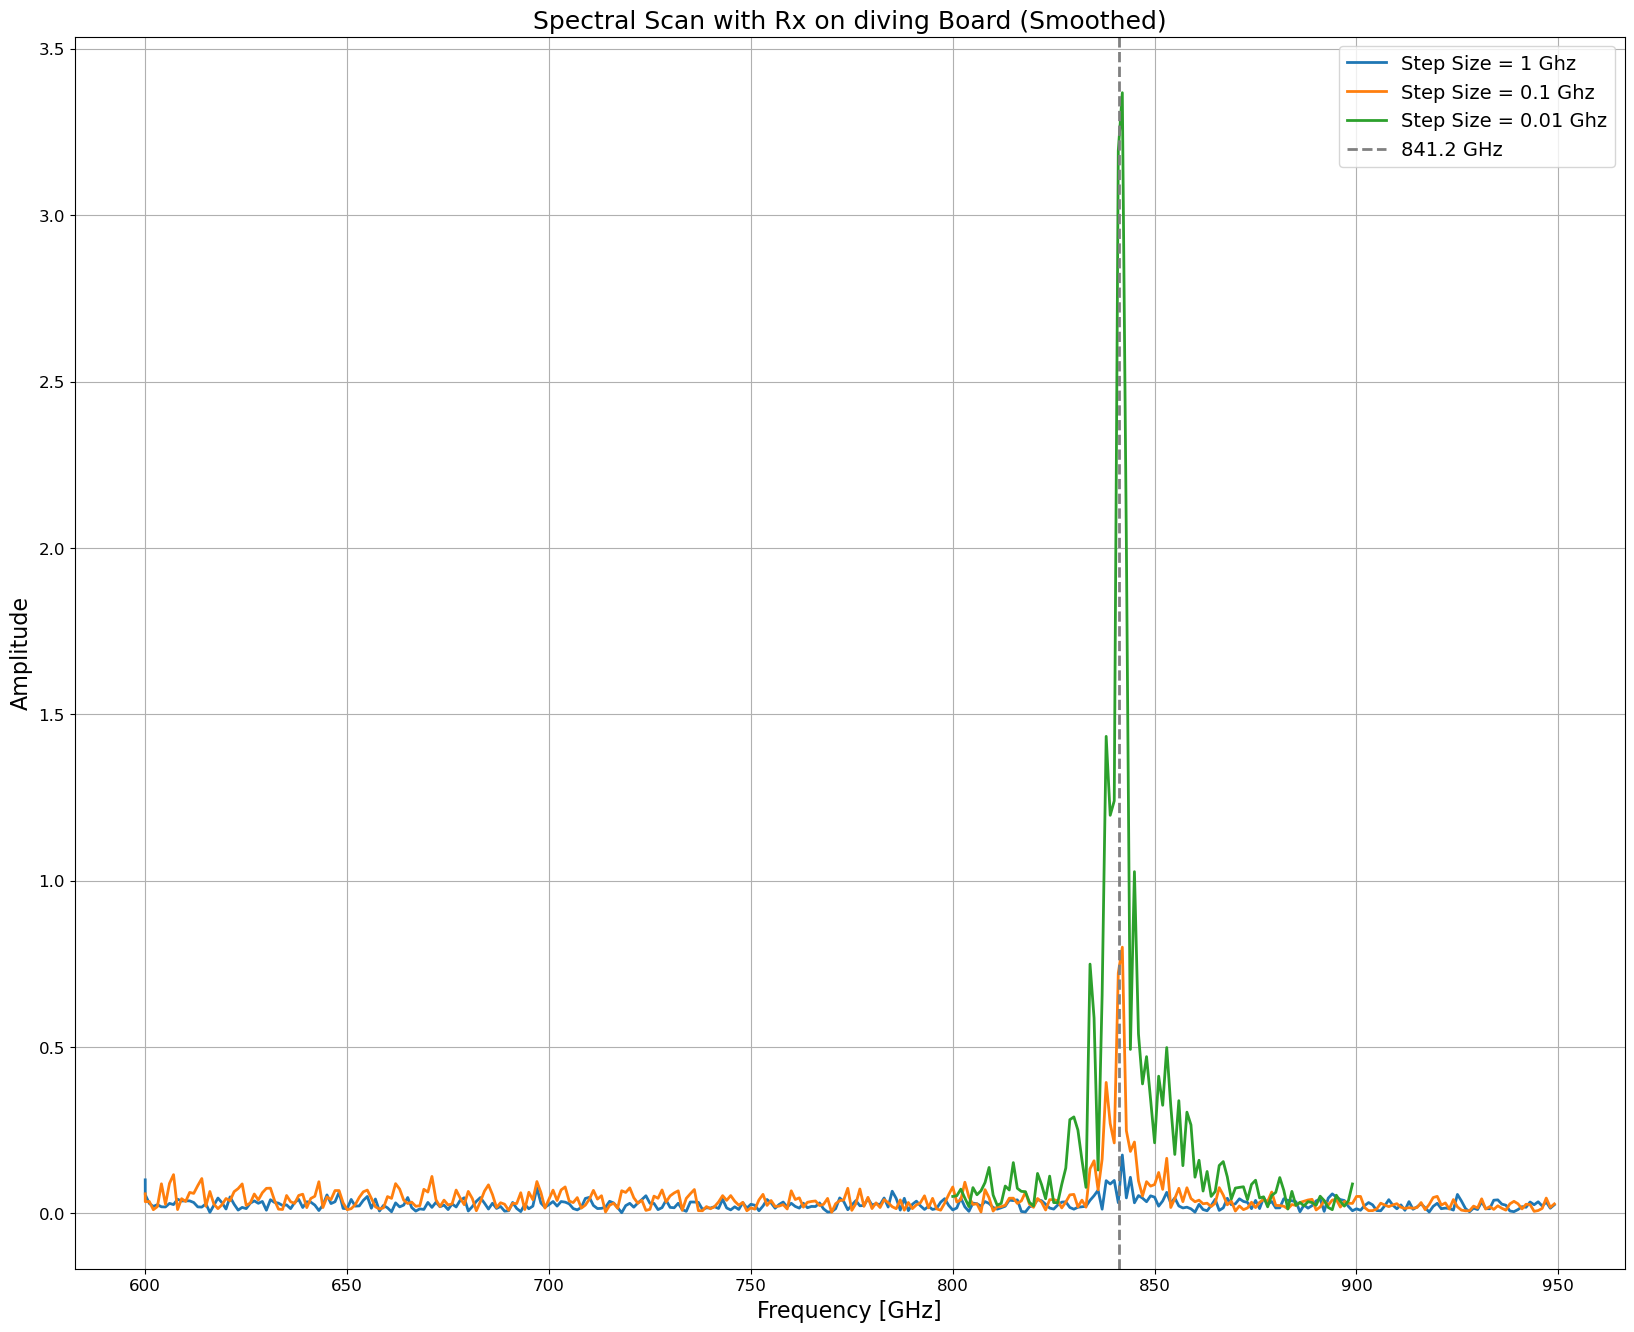

In [16]:
plt.figure(figsize=(20,16))
plt.plot(grid_frequencies, np.abs(warm_smooth_amps_1Ghz), label="Step Size = 1 Ghz", lw=2)
plt.plot(grid_frequencies, np.abs(warm_smooth_amps_pt1Ghz), label="Step Size = 0.1 Ghz", lw=2)
plt.plot(grid_frequencies[mask], np.abs(warm_smooth_amps_pt01Ghz), label="Step Size = 0.01 Ghz", lw=2)
plt.axvline(841.2, color="gray", ls="--", lw=2, label="841.2 GHz", alpha=1)
plt.legend(fontsize=14)
plt.xlabel("Frequency [GHz]", fontsize = 16)
plt.ylabel(r"Amplitude", fontsize = 16)
plt.title("Spectral Scan with Rx on diving Board (Smoothed)", fontsize = 18)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.grid()

plt.show()

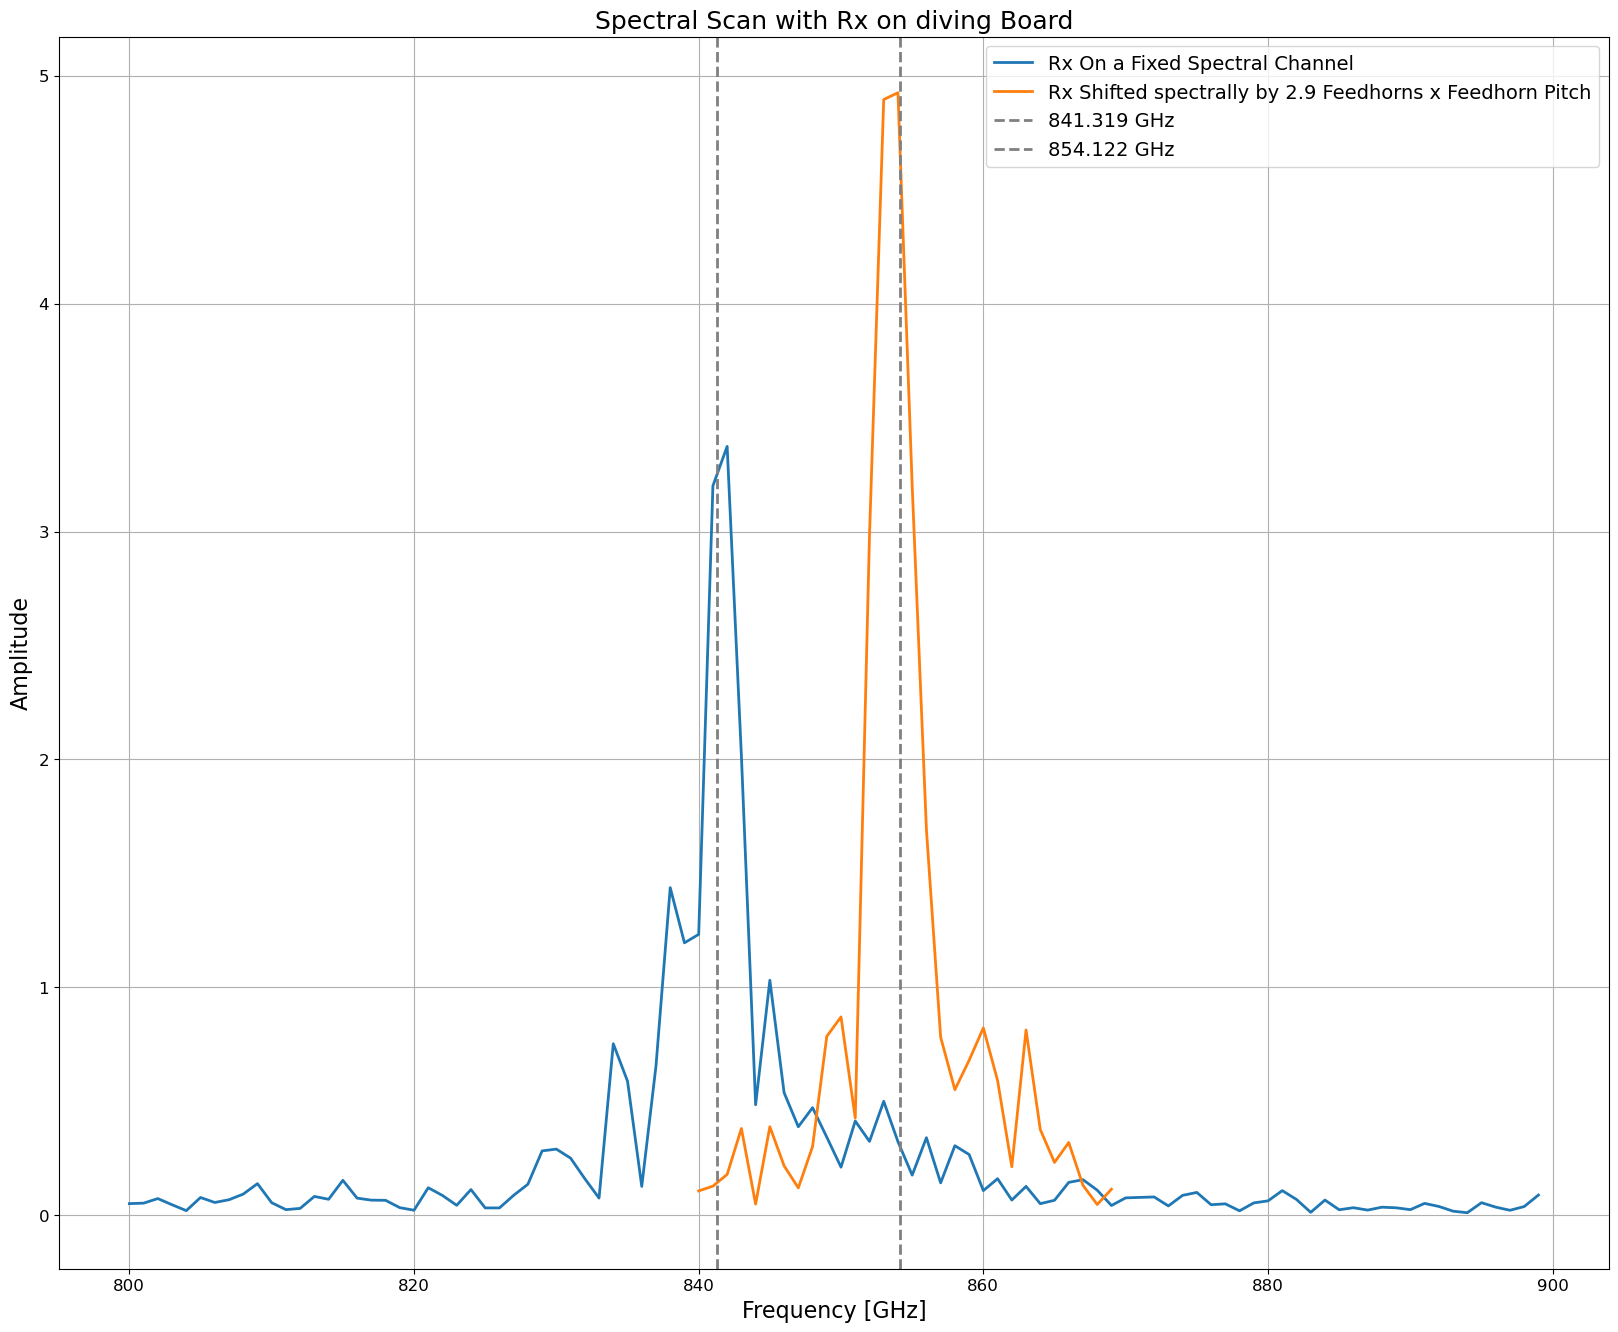

In [17]:
plt.figure(figsize=(20,16))
# plt.plot(grid_frequencies, np.abs(warm_1_Ghz_dt_phasor), label="Step Size = 1 Ghz", lw=2)
# plt.plot(grid_frequencies, np.abs(warm_pt1_Ghz_dt_phasor), label="Step Size = 0.1 Ghz", lw=2)
plt.plot(grid_frequencies[mask], np.abs(warm_pt01_Ghz_dt_phasor), label="Rx On a Fixed Spectral Channel", lw=2)
plt.plot(grid_frequencies[mask2], np.abs(warm_pt01_shifted_Ghz_dt_phasor), label="Rx Shifted spectrally by 2.9 Feedhorns x Feedhorn Pitch", lw=2)
plt.axvline(841.319, color="gray", ls="--", lw=2, label="841.319 GHz", alpha=1)
plt.axvline(854.122, color="gray", ls="--", lw=2, label="854.122 GHz", alpha=1)
plt.legend(fontsize=14)
plt.xlabel("Frequency [GHz]", fontsize = 16)
plt.ylabel(r"Amplitude", fontsize = 16)
plt.title("Spectral Scan with Rx on diving Board", fontsize = 18)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.grid()
plt.show()